# **CUSTOMER EXPERIENCE**

We have a hypothesis on the table and we need to answer the following questions:
- Did the Test experience achieve its business objective?
- What is the estimated impact on the primary KPI and guardrail metrics?
- How confident are you in the result?
- Are there any data-quality or experiment-design considerations that affect your interpretation?
- Would you recommend rolling out the new experience? Explain your reasoning and propose the next steps.

## Metodology

**Objective**

Check whether the new customer experience affects customers’ spending without negatively impacting their purchasing behaviour.

**Main Metric**

Revenue per assigned costumer (*Total revenue during the experiment / Nº of customers assigned to the group*)

There must be a relative increase of at least 2% that is commercially significant.

Let (`RAC_T`) and (`RAC_C`) denote the metric for the treatment and control groups, respectively.

- Null hypothesis: the difference in the RAC is less than or equal to 2%.
- Alternative hypothesis: the difference in the RAC is greater than 2%.


**Guardrail metrics**

- Conversion rate: (`H_0`) = the conversion rate deteriorates by 1% or more.
- Orders per assigned customer: (`H_0`) = Orders per customer are falling by at least 1% in relative terms.

**Diagnostic metrics**
- AVG order value
- Items per order
- Customer-level revenue distribution
- Results by customer characteristics or over time

## EDA

### Data import

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
# Data Ingestion
ab_assign = pd.read_csv("../data/raw/ab_assignment.csv")
cust_prof = pd.read_csv("../data/raw/customer_profile.csv")
transactions = pd.read_csv("../data/raw/transactions.csv")

###### AB_ASSIGNMENT SET

In [3]:
ab_assign.head()

,customer_id,group,assignment_date
0,C014479,control,2026-02-01
1,C045298,control,2026-02-01
2,C007346,control,2026-02-01
3,C015631,control,2026-02-01
4,C019112,control,2026-02-01


In [4]:
ab_assign.info()

<class 'pandas.DataFrame'>
RangeIndex: 100250 entries, 0 to 100249
Data columns (total 3 columns):
 #   Column           Non-Null Count   Dtype
---  ------           --------------   -----
 0   customer_id      100250 non-null  str  
 1   group            100250 non-null  str  
 2   assignment_date  100250 non-null  str  
dtypes: str(3)
memory usage: 4.5 MB


In [5]:
ab_assign.describe().T

,count,unique,top,freq
customer_id,100250,100000,C094522,2
group,100250,2,control,52525
assignment_date,100250,1,2026-02-01,100250


There are 250 customers who appears twice in the dataset.

In [6]:
# Identify duplicated customers in the dataset
duplicated_customers = (
    ab_assign["customer_id"]
    .value_counts()
    .loc[lambda x: x > 1]
)
duplicated_customers

customer_id
C094522    2
C048853    2
C098525    2
C084697    2
C026373    2
          ..
C079697    2
C022204    2
C045718    2
C054166    2
C098421    2
Name: count, Length: 250, dtype: int64

In [7]:
# Count the number of unique customers in each group
ab_assign.groupby("group")["customer_id"].nunique()

group
control    52445
test       47645
Name: customer_id, dtype: int64

In [8]:
# Identify customers assigned to multiple groups
groups_per_customer = (
    ab_assign.groupby("customer_id")["group"].nunique().sort_values(ascending=False)
)

customers_multiple_groups = groups_per_customer[
    groups_per_customer > 1
].index

len(customers_multiple_groups)

90

In [9]:
# Summary
customer_audit = (
    ab_assign.groupby("customer_id")
    .agg(
        n_records=("customer_id", "size"),
        n_groups=("group", "nunique"),
        n_dates=("assignment_date", "nunique"),
    )
)

print("One row:",
      (customer_audit["n_records"] == 1).sum())

print("Multiple rows:",
      (customer_audit["n_records"] > 1).sum())

print("Present in multiple groups:",
      (customer_audit["n_groups"] > 1).sum())

print("Multiple dates:",
      (customer_audit["n_dates"] > 1).sum())

print("Control Customers:", (ab_assign.groupby("group")["customer_id"].nunique().iloc[0]))
print("Test Customers:", (ab_assign.groupby("group")["customer_id"].nunique().iloc[1]))


One row: 99750
Multiple rows: 250
Present in multiple groups: 90
Multiple dates: 0
Control Customers: 52445
Test Customers: 47645


Data quality issue: 250 additional records have been identified in relation to the number of unique clients in the allocation dataset. Some clients have multiple records, and there are 90 cases where clients have been allocated to different experimental groups. The cause must be investigated before validating the allocation and carrying out the statistical analysis.

In [10]:
# Drop duplicated rows
ab_assign = ab_assign.drop_duplicates().copy()

In [11]:
# Remove customers present in multiple groups
ab_assign = ab_assign[~ab_assign["customer_id"].isin(customers_multiple_groups)].copy()
ab_assign

,customer_id,group,assignment_date
0,C014479,control,2026-02-01
1,C045298,control,2026-02-01
2,C007346,control,2026-02-01
3,C015631,control,2026-02-01
4,C019112,control,2026-02-01
...,...,...,...
100245,C068107,control,2026-02-01
100246,C014228,test,2026-02-01
100247,C048240,control,2026-02-01
100248,C075999,control,2026-02-01


In [12]:
# Check the resulting DataFrame
ab_assign.describe().T

,count,unique,top,freq
customer_id,99910,99910,C014479,1
group,99910,2,control,52355
assignment_date,99910,1,2026-02-01,99910


In [13]:
# Customers per group after removing duplicates and multiple group assignments
ab_assign.groupby("group")["customer_id"].nunique()

group
control    52355
test       47555
Name: customer_id, dtype: int64

In [14]:
# Chi-square test for equal distribution of customers between control and test groups (Sample Ratio Mismatch)
from scipy.stats import chisquare

observed = ab_assign.groupby("group")["customer_id"].nunique()

counts = observed.reindex(["control", "test"])

result = chisquare(
    f_obs=counts.values,
    f_exp=[49955, 49955]
)

print("Recuentos:", counts.to_dict())
print("Chi-cuadrado:", result.statistic)
print("p-value:", result.pvalue)

Recuentos: {'control': 52355, 'test': 47555}
Chi-cuadrado: 230.6075467921129
p-value: 4.393873055186228e-52


Initially, I considered undersampling to force a 50-50 symmetrical design, but I decided to retain all the samples (52k vs 47k) so as not to waste valuable information.
d.

Although there is a statistically significant difference between the samples in terms of sampling. Initially, I considered undersampling to force a 50-50 symmetrical design, but I decided to assum this because removing customers would mean losing valuable information.

We need to look more closely at the data collection and sampling process to justify this imbalance.

In [15]:
ab_assign.dtypes

customer_id        str
group              str
assignment_date    str
dtype: object

In [16]:
ab_assign["assignment_date"] = pd.to_datetime(ab_assign["assignment_date"], dayfirst=True)
ab_assign.dtypes

customer_id                   str
group                         str
assignment_date    datetime64[us]
dtype: object

In [17]:
# Save the cleaned dataset of assignements on intermediate folder in parquet format
import pyarrow
ab_assign.to_parquet("../data/intermediate/ab_assign.parquet", index=False)

___

###### CUST_PROF

In [18]:
cust_prof.head(5)

,customer_id,historical_value_segment,gender,age,region,registration_date
0,C000001,High,Male,36.0,West,2024-08-07
1,C000002,High,Male,35.0,South,2024-01-16
2,C000003,Medium,Male,49.0,East,2023-03-20
3,C000004,Medium,Male,54.0,West,2025-10-01
4,C000005,Medium,Female,20.0,South,2022-08-21


In [19]:
cust_prof.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   customer_id               100000 non-null  str    
 1   historical_value_segment  100000 non-null  str    
 2   gender                    100000 non-null  str    
 3   age                       97953 non-null   float64
 4   region                    100000 non-null  str    
 5   registration_date         100000 non-null  str    
dtypes: float64(1), str(5)
memory usage: 7.5 MB


In [20]:
cust_prof.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,100000,100000,C000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
historical_value_segment,100000,3,Medium,47578,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,100000,2,Female,50177,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,97953.0,NaN,NaN,NaN,43.162088,12.638345,18.0,34.0,43.0,52.0,82.0
region,100000,4,South,25846,NaN,NaN,NaN,NaN,NaN,NaN,NaN
registration_date,100000,1460,2023-02-05,95,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
# Duplicated rows
print(cust_prof.duplicated().sum())

0


From this summary overview, several points can be observed:
- Are 100000 unique customers, but we need to clean the customers that we remove from the ab_assignent set.
- Are 2047 rows with the `age` columns is null. The range is between 18 and 82 years old.
- All costumers have been registered before the registration date on the assignment moment.

In [22]:
# Convert registration_date to datetime format to optimize date operations
cust_prof["registration_date"] = pd.to_datetime(cust_prof["registration_date"])
cust_prof.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   customer_id               100000 non-null  str           
 1   historical_value_segment  100000 non-null  str           
 2   gender                    100000 non-null  str           
 3   age                       97953 non-null   float64       
 4   region                    100000 non-null  str           
 5   registration_date         100000 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(1), str(4)
memory usage: 6.6 MB


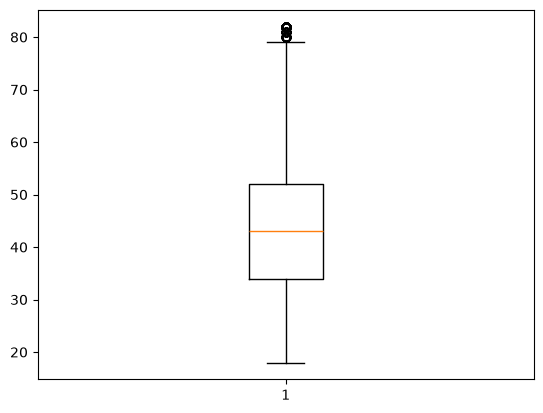

In [23]:
# Boxplot to see the distribution of age and identify outliers
f, ax = plt.subplots()
ax.boxplot(cust_prof["age"].dropna())
plt.show()

In [24]:
# We have to identify the last observed value that does not exceed the upper limit (upper whisker)
q1 = cust_prof["age"].quantile(0.25)
q3 = cust_prof["age"].quantile(0.75)

iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

# Last value observed that does not exceed the upper limit (upper whisker)
upper_whisker = cust_prof.loc[
    cust_prof["age"] <= upper_limit, "age"
].max()

print(upper_limit)
print(upper_whisker)

79.0
79.0


In [25]:
# Customers with age 78 or older
print(
    cust_prof.loc[cust_prof["age"] >= 78, "age"]
    .value_counts()
    .sort_index()
)

age
78.0     75
79.0     54
80.0     51
81.0     41
82.0    138
Name: count, dtype: int64


Although there are some customers over 78 years of age, this is entirely plausible, so don't requires any treatment.

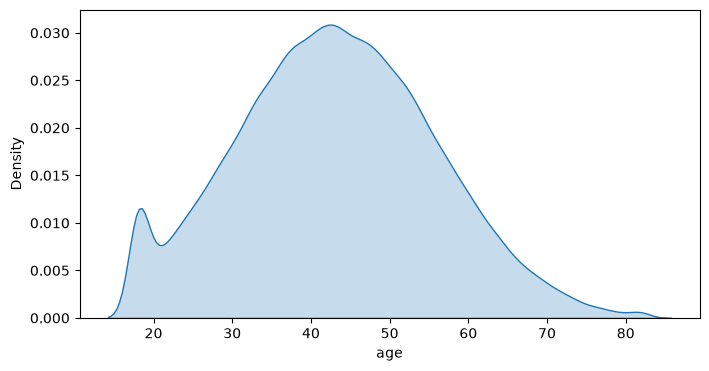

In [26]:
# Distribution of age 
plt.figure(figsize=(8, 4))
sns.kdeplot(data=cust_prof, x="age", fill=True)
plt.show()

In [27]:
# Impute missing age values with the median
median_age = cust_prof["age"].median()
cust_prof["age"]  = cust_prof["age"].fillna(median_age)

In [28]:
# Convert age column to integer type after imputing missing values
cust_prof["age"] = cust_prof["age"].astype(int)
print(cust_prof["age"].dtype)

int64


In [29]:
cust_prof.to_parquet("../data/intermediate/cust_prof.parquet", index=False)

___

###### TRANSACTIONS

In [30]:
transactions.head()

,order_id,customer_id,order_date,revenue,items
0,O00156992,C000079,2026-01-01,134.20,12
1,O00075667,C000092,2026-01-01,42.02,4
2,O00097638,C000112,2026-01-01,82.17,7
3,O00118647,C000144,2026-01-01,11.56,2
4,O00090463,C000172,2026-01-01,19.73,3


In [31]:
transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 177386 entries, 0 to 177385
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   order_id     177386 non-null  str    
 1   customer_id  177386 non-null  str    
 2   order_date   177386 non-null  str    
 3   revenue      177386 non-null  float64
 4   items        177386 non-null  int64  
dtypes: float64(1), int64(1), str(3)
memory usage: 11.2 MB


In [32]:
transactions.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,177386,177386,O00156992,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,177386,78266,C012783,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,177386,59,2026-02-02,3415,NaN,NaN,NaN,NaN,NaN,NaN,NaN
revenue,177386.0,NaN,NaN,NaN,56.702554,91.214334,2.72,28.8,45.07,70.09,7661.31
items,177386.0,NaN,NaN,NaN,5.613921,9.113448,1.0,3.0,5.0,7.0,827.0


In [33]:
# Convert order_date column to datetime format
transactions["order_date"] = pd.to_datetime(transactions["order_date"])

In [34]:
transactions["order_date"].min()

Timestamp('2026-01-01 00:00:00')

In [35]:
# Filter transactions for February 2026
transactions = transactions[transactions["order_date"].between(pd.to_datetime("2026-02-01"), pd.to_datetime("2026-02-28"))].copy()

In [36]:
transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 86498 entries, 90888 to 177385
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_id     86498 non-null  str           
 1   customer_id  86498 non-null  str           
 2   order_date   86498 non-null  datetime64[us]
 3   revenue      86498 non-null  float64       
 4   items        86498 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 4.6 MB


In [37]:
transactions.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,86498,86498,O00118578,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,86498,54947,C060614,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,86498,NaN,NaN,NaN,2026-02-14 03:15:06.721542,2026-02-01 00:00:00,2026-02-07 00:00:00,2026-02-14 00:00:00,2026-02-21 00:00:00,2026-02-28 00:00:00,NaN
revenue,86498.0,NaN,NaN,NaN,57.89679,2.75,28.81,45.0,70.12,7661.31,123.963554
items,86498.0,NaN,NaN,NaN,5.729497,1.0,3.0,5.0,7.0,827.0,12.354056


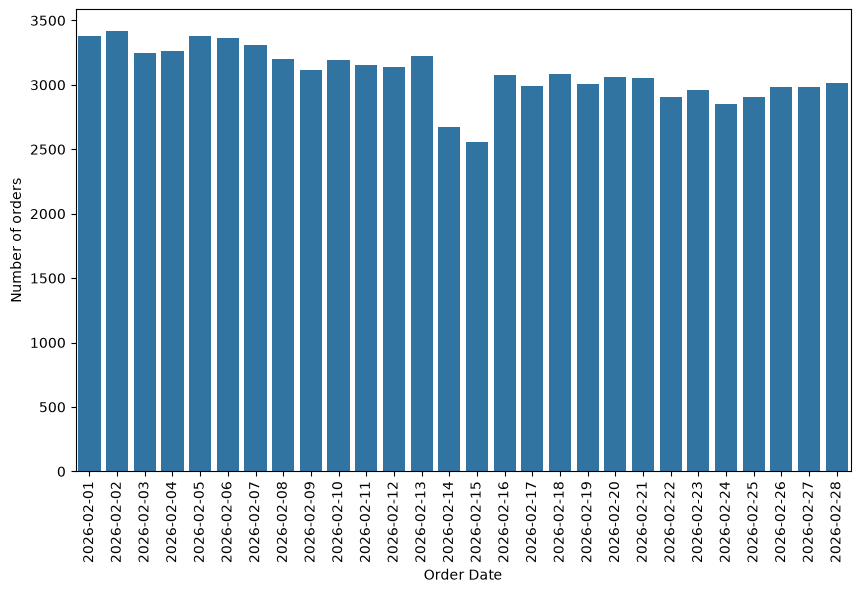

In [38]:
# Plot the number of orders per day in February 2026
f, ax = plt.subplots(figsize=(10, 6))
sns.countplot(data=transactions, x="order_date", ax=ax)
ax.set_xlabel("Order Date", fontsize=10)
plt.xticks(rotation=90)
ax.set_ylabel("Number of orders")
plt.show()

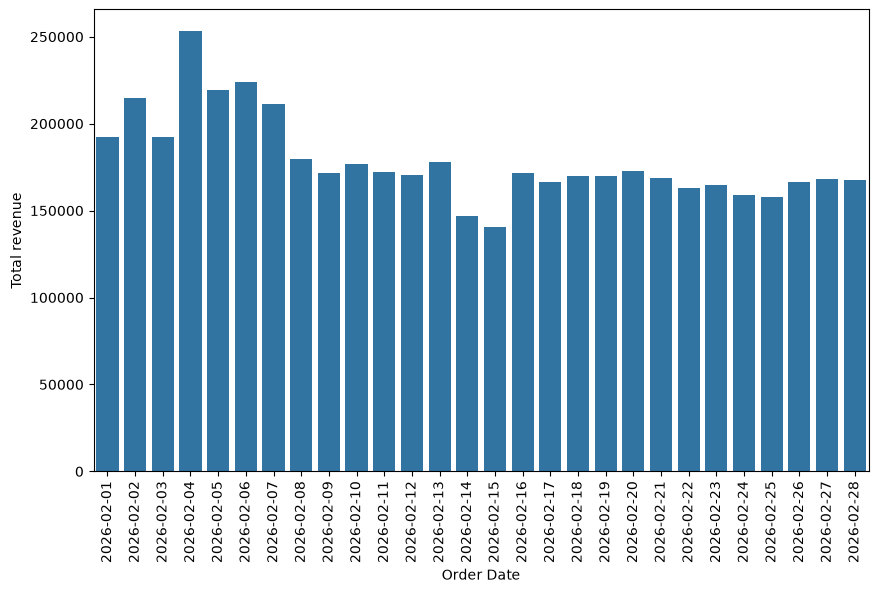

In [39]:
# Plot the total revenue per day in February 2026
daily_rev = transactions.groupby("order_date")["revenue"].sum().reset_index()

f, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=daily_rev, x="order_date", ax=ax, y = "revenue")
ax.set_xlabel("Order Date", fontsize=10)
plt.xticks(rotation=90)
ax.set_ylabel("Total revenue")
plt.show()

In [40]:
# Revenue by customer
transactions.groupby("customer_id")["revenue"].sum().sort_values(ascending=False)

customer_id
C029859    7697.24
C063410    7631.80
C003194    7608.11
C079147    7561.67
C002954    7522.26
            ...   
C095982       4.02
C028006       4.00
C021701       3.87
C051545       3.68
C036217       2.75
Name: revenue, Length: 54947, dtype: float64

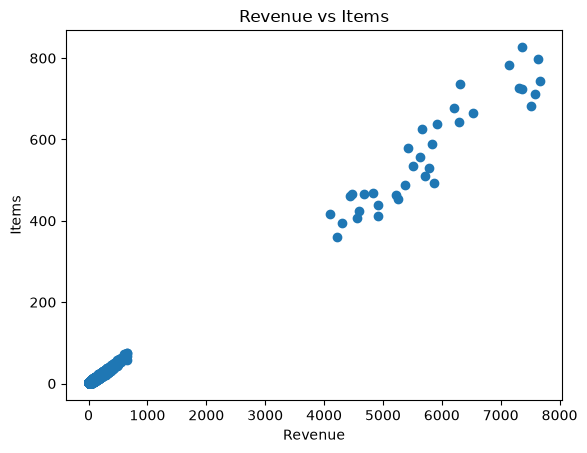

In [41]:
# Correlation between revenue and items
plt.scatter(transactions["revenue"], transactions["items"])
plt.xlabel("Revenue")
plt.ylabel("Items")
plt.title("Revenue vs Items")
plt.show()

In [42]:
# Save transactions DataFrame to parquet file in the intermediate data folder
transactions.to_parquet("../data/intermediate/transactions.parquet")

___